# 🧪 EDA — Dataset Jalur VOC (aseton napas)

Berbeda dari jalur detak jantung yang memakai dataset unduhan, jalur VOC
dibangun dari **persamaan regresi terukur** yang diterbitkan pada:

> Turner C, Walton C, Hoashi S, Evans M.
> *Breath acetone concentration decreases with blood glucose concentration
> in type I diabetes mellitus patients during hypoglycaemic clamps.*
> Open University & Cambridge University (didanai JDRF & Wellcome Trust).

Studi *insulin clamp* pada **8 pasien diabetes tipe 1**: glukosa diturunkan
bertahap 5 → 3,8 → 3,3 → 2,8 → 2,4 mmol/L hingga memasuki rentang
hipoglikemia, aseton napas diukur dengan **SIFT-MS** (spektrometri massa).

**Tujuan telaah ini — empat pertanyaan:**
1. Seberapa berbeda kadar aseton antar-orang pada glukosa yang serupa?
2. Apakah simulasi kami setia pada parameter yang diterbitkan?
3. Apakah membaca aseton secara relatif memang lebih baik daripada mutlak?
4. Apakah sensor kami mampu membaca rentang kadar tersebut?


In [ ]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AKAR = r'C:\KULIAH\BELAJAR NGODING\HypoSense\HypoSense'
sys.path.insert(0, os.path.join(AKAR, 'analysis', 'model'))
from pipeline_voc import TURNER, buat_data_turner, tambah_fitur, HIPO_MMOL

BIRU, JINGGA, MERAH = '#3B6CFF', '#E8833A', '#B3261E'
TINTA2, GARIS = '#5a5a5a', '#d8d8d8'
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb',
    'axes.edgecolor': GARIS, 'axes.labelcolor': TINTA2,
    'xtick.color': TINTA2, 'ytick.color': TINTA2, 'font.size': 9,
})
print(f'Batas hipoglikemia: {HIPO_MMOL} mmol/L  (= {HIPO_MMOL*18:.0f} mg/dL)')


Batas hipoglikemia: 3.9 mmol/L  (= 70 mg/dL)


---
# BAGIAN 1 — Data terukur dari makalah

## 1.1 Kadar awal (Tabel 1 makalah)

Kadar glukosa dan aseton napas **sebelum** glukosa diturunkan.
Ini pengukuran sungguhan, bukan simulasi.


In [ ]:
# Tabel 1 Turner dkk. — 8 sukarelawan, kondisi awal sebelum clamp
tabel1 = pd.DataFrame({
    'subjek':        ['4A', '5A', '1B', '8A', '7B', '6B', '10A', '11A'],
    'glukosa_mmol':  [8.0, 5.8, 13.9, 5.7, 7.0, 4.8, 5.8, 5.0],
    'aseton_ppm':    [1.2, 3.4, 8.5, 1.7, 4.3, 3.5, 21.0, 1.0],
})
tabel1['glukosa_mgdl'] = (tabel1.glukosa_mmol * 18).round(0).astype(int)
tabel1

,subjek,glukosa_mmol,aseton_ppm,glukosa_mgdl
0,4A,8.0,1.2,144
1,5A,5.8,3.4,104
2,1B,13.9,8.5,250
3,8A,5.7,1.7,103
4,7B,7.0,4.3,126
5,6B,4.8,3.5,86
6,10A,5.8,21.0,104
7,11A,5.0,1.0,90


In [ ]:
a = tabel1.aseton_ppm
print(f'Rentang aseton antar-subjek : {a.min()} - {a.max()} ppm')
print(f'Rasio tertinggi/terendah    : {a.max()/a.min():.0f} kali lipat')
print(f'Median                      : {a.median()} ppm')
print()
print('Rujukan orang sehat menurut makalah: ~0,3-0,9 ppm')
print(f'Subjek dengan kadar dalam rentang sehat: {(a <= 2.0).sum()} dari {len(a)}')
print()
print('=> Temuan makalah: anggapan bahwa penderita diabetes SELALU')
print('   berkadar aseton tinggi ternyata tidak selalu benar.')


Rentang aseton antar-subjek : 1.0 - 21.0 ppm
Rasio tertinggi/terendah    : 21 kali lipat
Median                      : 3.45 ppm

Rujukan orang sehat menurut makalah: ~0,3-0,9 ppm
Subjek dengan kadar dalam rentang sehat: 3 dari 8

=> Temuan makalah: anggapan bahwa penderita diabetes SELALU
   berkadar aseton tinggi ternyata tidak selalu benar.


## 1.2 Pertanyaan 1 — apakah kadar aseton bisa dipakai antar-orang?

Bila kadar aseton berkorelasi dengan glukosa **antar individu**, maka satu
nilai ambang untuk semua orang dimungkinkan. Mari diperiksa.


Korelasi Pearson antar-subjek : r = 0.134
Dilaporkan pada makalah        : r = 0,134
Selisih                        : 0.0001  -> cocok

r = 0,134 berarti hubungannya PRAKTIS NIHIL.


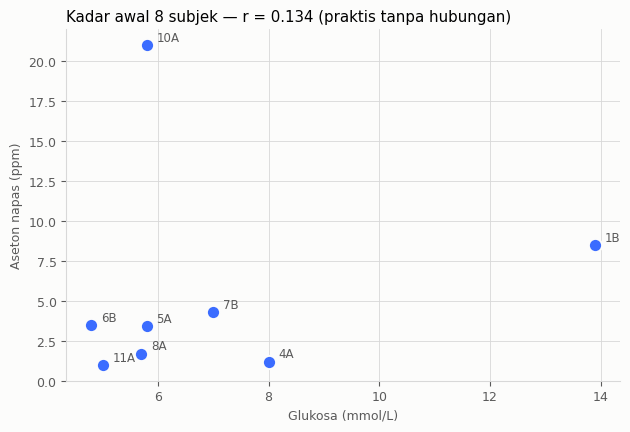


KESIMPULAN: subjek 10A berkadar 21 ppm dan subjek 11A berkadar 1 ppm
pada glukosa yang hampir sama (5,8 vs 5,0 mmol/L). Ambang tunggal
untuk semua orang TIDAK MUNGKIN dibuat.


In [ ]:
r = np.corrcoef(tabel1.glukosa_mmol, tabel1.aseton_ppm)[0, 1]
print(f'Korelasi Pearson antar-subjek : r = {r:.3f}')
print(f'Dilaporkan pada makalah        : r = 0,134')
print(f'Selisih                        : {abs(r - 0.134):.4f}  -> cocok')
print()
print('r = 0,134 berarti hubungannya PRAKTIS NIHIL.')

fig, ax = plt.subplots(figsize=(6.4, 4.4))
ax.scatter(tabel1.glukosa_mmol, tabel1.aseton_ppm, s=90, color=BIRU,
           edgecolor='#fcfcfb', linewidth=1.4, zorder=3)
for _, b in tabel1.iterrows():
    ax.annotate(b.subjek, (b.glukosa_mmol, b.aseton_ppm), xytext=(7, 3),
                textcoords='offset points', fontsize=8.5, color=TINTA2)
ax.set_title(f'Kadar awal 8 subjek — r = {r:.3f} (praktis tanpa hubungan)',
             loc='left')
ax.set_xlabel('Glukosa (mmol/L)'); ax.set_ylabel('Aseton napas (ppm)')
ax.grid(color=GARIS, lw=0.6); ax.set_axisbelow(True)
for s in ('top','right'): ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print()
print('KESIMPULAN: subjek 10A berkadar 21 ppm dan subjek 11A berkadar 1 ppm')
print('pada glukosa yang hampir sama (5,8 vs 5,0 mmol/L). Ambang tunggal')
print('untuk semua orang TIDAK MUNGKIN dibuat.')


## 1.3 Persamaan regresi per subjek

Meski antar-orang tidak berhubungan, **di dalam diri satu orang** makalah
melaporkan hubungan yang kuat. Berikut persamaan yang diterbitkan.


In [ ]:
reg = pd.DataFrame(TURNER, columns=['subjek','kemiringan','intersep','R2','glukosa_awal'])
reg['persamaan'] = reg.apply(
    lambda b: f"aseton = {b.kemiringan:.1f} x glukosa + {b.intersep:.1f}", axis=1)
print(f'Jumlah subjek dengan persamaan : {len(reg)}')
print(f'Rentang R2                     : {reg.R2.min():.3f} - {reg.R2.max():.3f}')
print(f'Rata-rata R2                   : {reg.R2.mean():.3f}')
print()
print('Catatan: makalah mengeluarkan satu titik awal subjek 4A dari analisis')
print('karena glukosanya sedang berubah cepat menjelang clamp dimulai.')
reg[['subjek','persamaan','R2','glukosa_awal']]


Jumlah subjek dengan persamaan : 7
Rentang R2                     : 0.598 - 0.940
Rata-rata R2                   : 0.832

Catatan: makalah mengeluarkan satu titik awal subjek 4A dari analisis
karena glukosanya sedang berubah cepat menjelang clamp dimulai.


,subjek,persamaan,R2,glukosa_awal
0,4A,aseton = 241.5 x glukosa + 665.0,0.854,5.5
1,1B,aseton = 317.1 x glukosa + 3770.2,0.884,13.9
2,5A,aseton = 410.6 x glukosa + 928.2,0.903,5.8
3,8A,aseton = 201.9 x glukosa + 507.7,0.780,5.7
4,7B,aseton = 337.0 x glukosa + 2288.2,0.598,7.0
5,6B,aseton = 724.4 x glukosa + -429.6,0.862,4.8
6,10A,aseton = 2770.9 x glukosa + 4783.5,0.940,5.8


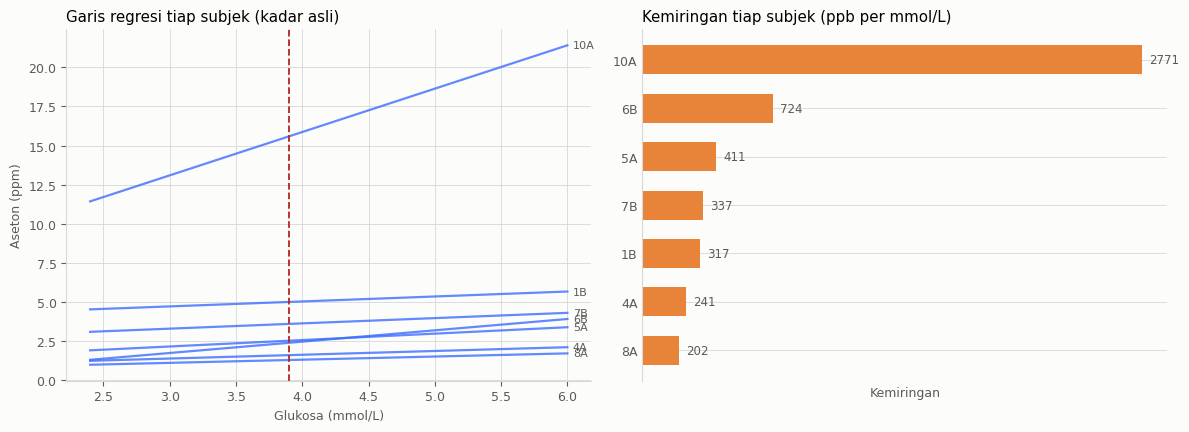

Kemiringan terendah : 202 ppb per mmol/L
Kemiringan tertinggi: 2771 ppb per mmol/L
Rasio               : 14 kali

Arah kemiringan SEMUANYA POSITIF: aseton TURUN saat glukosa turun.
Inilah dasar peran VOC sebagai pembeda arah, bukan pendeteksi hipo.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

# kiri: garis regresi tiap subjek (skala asli)
g = np.linspace(2.4, 6.0, 50)
for _, b in reg.iterrows():
    axes[0].plot(g, (b.kemiringan*g + b.intersep)/1000, color=BIRU, lw=1.6, alpha=0.8)
    axes[0].annotate(b.subjek, (g[-1], (b.kemiringan*g[-1]+b.intersep)/1000),
                     xytext=(4,0), textcoords='offset points', fontsize=8,
                     color=TINTA2, va='center')
axes[0].axvline(HIPO_MMOL, color=MERAH, lw=1.3, ls='--')
axes[0].set_title('Garis regresi tiap subjek (kadar asli)', loc='left')
axes[0].set_xlabel('Glukosa (mmol/L)'); axes[0].set_ylabel('Aseton (ppm)')

# kanan: kemiringan tiap subjek
p = reg.sort_values('kemiringan')
axes[1].barh(p.subjek, p.kemiringan, color=JINGGA, height=0.6)
for i, v in enumerate(p.kemiringan):
    axes[1].text(v+40, i, f'{v:.0f}', va='center', fontsize=8.5, color=TINTA2)
axes[1].set_title('Kemiringan tiap subjek (ppb per mmol/L)', loc='left')
axes[1].set_xlabel('Kemiringan'); axes[1].set_xticks([])
for a2 in axes:
    a2.grid(color=GARIS, lw=0.6); a2.set_axisbelow(True)
    for s in ('top','right'): a2.spines[s].set_visible(False)
axes[1].spines['bottom'].set_visible(False); axes[1].tick_params(length=0)
plt.tight_layout(); plt.show()

print(f'Kemiringan terendah : {reg.kemiringan.min():.0f} ppb per mmol/L')
print(f'Kemiringan tertinggi: {reg.kemiringan.max():.0f} ppb per mmol/L')
print(f'Rasio               : {reg.kemiringan.max()/reg.kemiringan.min():.0f} kali')
print()
print('Arah kemiringan SEMUANYA POSITIF: aseton TURUN saat glukosa turun.')
print('Inilah dasar peran VOC sebagai pembeda arah, bukan pendeteksi hipo.')


---
# BAGIAN 2 — Verifikasi simulasi

## 2.1 Pertanyaan 2 — apakah simulasi setia pada parameter terbitan?

Data pemodelan dibangkitkan dari persamaan di atas, dengan derau yang
dikalibrasi agar R² hasil simulasi menyerupai R² yang dilaporkan.
**Pemeriksaan ini memastikan pembangkitannya benar** — bukan sekadar
angka yang kebetulan terlihat masuk akal.


In [ ]:
sim = tambah_fitur(buat_data_turner())
print(f'Sampel   : {len(sim)}')
print(f'Subjek   : {sim.subject.nunique()}')
print(f'Hipo     : {sim.label.sum()} ({sim.label.mean():.0%})')
print(f'Aseton   : {sim.acetone_ppb.min():.0f} - {sim.acetone_ppb.max():.0f} ppb')
sim.head()


Sampel   : 420
Subjek   : 7
Hipo     : 179 (43%)
Aseton   : 946 - 20427 ppb


,subject,glucose_mmol,acetone_ppb,acetone_rel,label
0,10A,4.337894,17117.093722,-0.080947,0
1,10A,2.815555,12585.162352,-0.324276,1
2,10A,5.491172,20427.434894,0.096792,0
3,10A,4.938829,18008.521407,-0.033084,0
4,10A,4.320789,16116.141145,-0.134690,0


In [ ]:
# Hitung ulang R2 dari data simulasi, bandingkan dengan yang diterbitkan
banding = []
for _, b in reg.iterrows():
    d = sim[sim.subject == b.subjek]
    if len(d) < 3: continue
    x, y = d.glucose_mmol.to_numpy(), d.acetone_ppb.to_numpy()
    k, c = np.polyfit(x, y, 1)
    sisa = np.sum((y - (k*x + c))**2)
    total = np.sum((y - y.mean())**2)
    banding.append({'subjek': b.subjek, 'R2_terbit': b.R2,
                    'R2_simulasi': round(1 - sisa/total, 3),
                    'kemiringan_terbit': round(b.kemiringan, 1),
                    'kemiringan_simulasi': round(k, 1)})
bd = pd.DataFrame(banding)
bd['selisih_R2'] = (bd.R2_simulasi - bd.R2_terbit).round(3)
print(f'Selisih R2 rata-rata (mutlak): {bd.selisih_R2.abs().mean():.3f}')
bd


Selisih R2 rata-rata (mutlak): 0.027


,subjek,R2_terbit,R2_simulasi,kemiringan_terbit,kemiringan_simulasi,selisih_R2
0,4A,0.854,0.831,241.5,214.7,-0.023
1,1B,0.884,0.914,317.1,339.8,0.030
2,5A,0.903,0.870,410.6,414.6,-0.033
3,8A,0.780,0.737,201.9,192.7,-0.043
4,7B,0.598,0.547,337.0,302.7,-0.051
5,6B,0.862,0.863,724.4,753.5,0.001
6,10A,0.940,0.929,2770.9,2828.0,-0.011


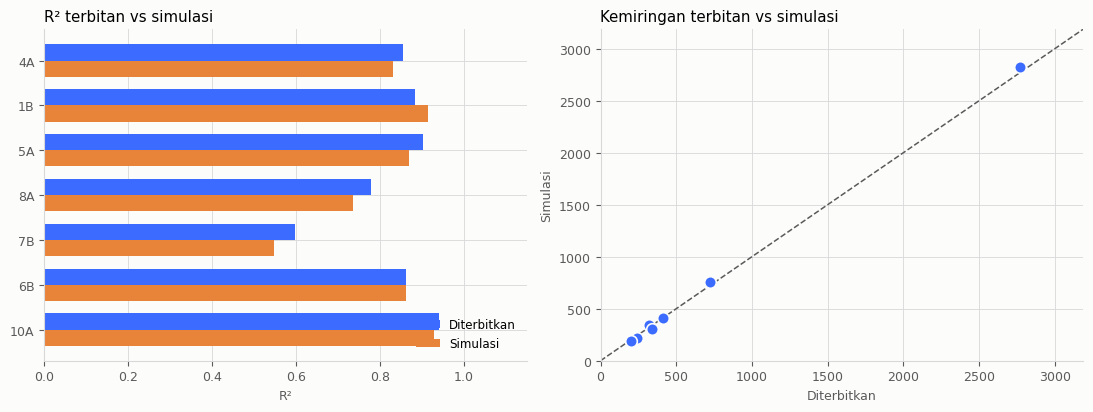

Titik-titik berhimpit dengan garis diagonal dan tinggi batang
berpasangan hampir sama => simulasi setia pada parameter terbitan.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

y = np.arange(len(bd)); h = 0.36
axes[0].barh(y - h/2, bd.R2_terbit, height=h, color=BIRU, label='Diterbitkan')
axes[0].barh(y + h/2, bd.R2_simulasi, height=h, color=JINGGA, label='Simulasi')
axes[0].set_yticks(y, bd.subjek); axes[0].invert_yaxis()
axes[0].set_xlim(0, 1.15); axes[0].set_xlabel('R²')
axes[0].set_title('R² terbitan vs simulasi', loc='left')
axes[0].legend(frameon=False, fontsize=8.5, loc='lower right')

lim = [0, bd.kemiringan_terbit.max()*1.15]
axes[1].plot(lim, lim, color=TINTA2, lw=1.1, ls='--')
axes[1].scatter(bd.kemiringan_terbit, bd.kemiringan_simulasi, s=70,
                color=BIRU, edgecolor='#fcfcfb', linewidth=1.2, zorder=3)
axes[1].set_title('Kemiringan terbitan vs simulasi', loc='left')
axes[1].set_xlabel('Diterbitkan'); axes[1].set_ylabel('Simulasi')
axes[1].set_xlim(lim); axes[1].set_ylim(lim)
for a2 in axes:
    a2.grid(color=GARIS, lw=0.6); a2.set_axisbelow(True)
    for s in ('top','right'): a2.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print('Titik-titik berhimpit dengan garis diagonal dan tinggi batang')
print('berpasangan hampir sama => simulasi setia pada parameter terbitan.')


In [ ]:
# Uji silang: apakah korelasi ANTAR-SUBJEK pada simulasi juga rendah,
# sebagaimana temuan makalah (r = 0,134)?
rata = sim.groupby('subject').agg(
    glukosa=('glucose_mmol','mean'), aseton=('acetone_ppb','mean'))
r_sim = np.corrcoef(rata.glukosa, rata.aseton)[0,1]
print(f'Korelasi antar-subjek pada simulasi : r = {r_sim:.3f}')
print(f'Korelasi antar-subjek pada makalah  : r = 0,134')
print()
print('Keduanya sama-sama rendah => sifat penting datanya ikut terbawa,')
print('bukan hanya bentuk garisnya.')


Korelasi antar-subjek pada simulasi : r = 0.119
Korelasi antar-subjek pada makalah  : r = 0,134

Keduanya sama-sama rendah => sifat penting datanya ikut terbawa,
bukan hanya bentuk garisnya.


---
# BAGIAN 3 — Pertanyaan 3: mutlak atau relatif?

Inti rancangan HypoSense: aseton dibaca sebagai **perubahan terhadap
patokan personal**, bukan kadar mutlak. Bagian ini memeriksa apakah
keputusan itu memang berdasar.


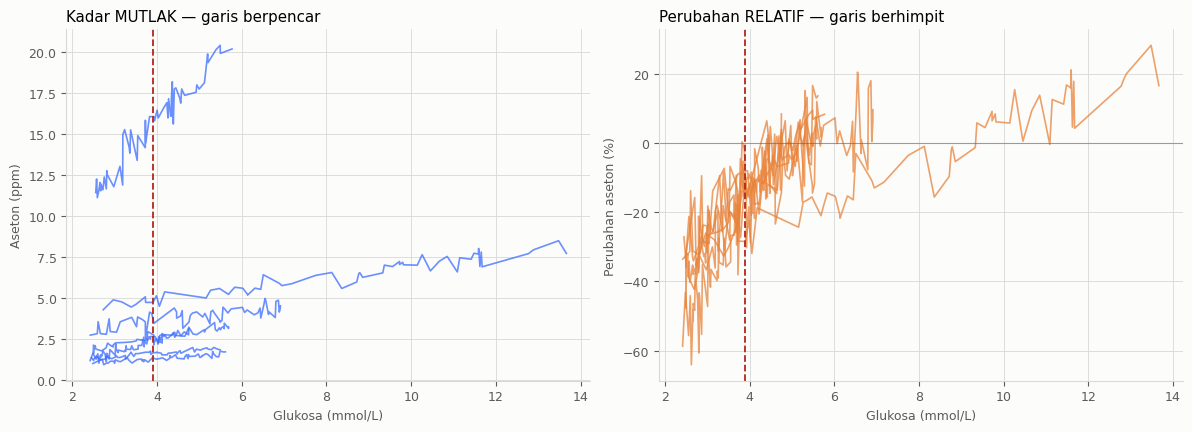

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

for _, d in sim.groupby('subject'):
    d = d.sort_values('glucose_mmol')
    axes[0].plot(d.glucose_mmol, d.acetone_ppb/1000, color=BIRU, lw=1.2, alpha=0.75)
    axes[1].plot(d.glucose_mmol, d.acetone_rel*100, color=JINGGA, lw=1.2, alpha=0.75)

axes[0].set_title('Kadar MUTLAK — garis berpencar', loc='left')
axes[0].set_ylabel('Aseton (ppm)')
axes[1].set_title('Perubahan RELATIF — garis berhimpit', loc='left')
axes[1].set_ylabel('Perubahan aseton (%)')
axes[1].axhline(0, color=TINTA2, lw=0.8, alpha=0.5)
for a2 in axes:
    a2.axvline(HIPO_MMOL, color=MERAH, lw=1.3, ls='--')
    a2.set_xlabel('Glukosa (mmol/L)')
    a2.grid(color=GARIS, lw=0.6); a2.set_axisbelow(True)
    for s in ('top','right'): a2.spines[s].set_visible(False)
plt.tight_layout(); plt.show()


Daya pisah antara kondisi hipoglikemia dan normal:
  Kadar mutlak      : d = 0.40
  Perubahan relatif : d = 2.11
  Peningkatan       : 5.3 kali

Panduan tafsir Cohen: 0,2 kecil | 0,5 sedang | 0,8 besar


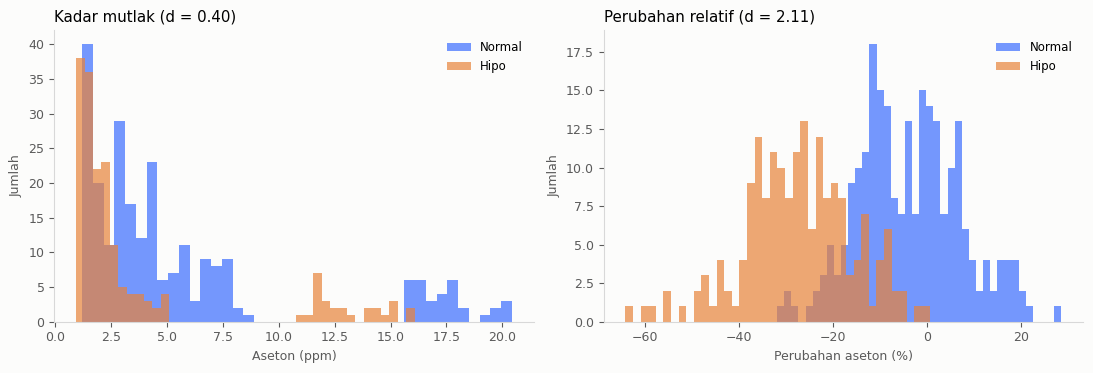

In [ ]:
# Seberapa jauh kedua kelas terpisah? Ukur dengan Cohen's d.
def cohen_d(a, b):
    sg = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1))
                 / (len(a)+len(b)-2))
    return (a.mean() - b.mean()) / sg

hipo, normal = sim[sim.label==1], sim[sim.label==0]
d_abs = cohen_d(hipo.acetone_ppb, normal.acetone_ppb)
d_rel = cohen_d(hipo.acetone_rel, normal.acetone_rel)

print('Daya pisah antara kondisi hipoglikemia dan normal:')
print(f'  Kadar mutlak      : d = {abs(d_abs):.2f}')
print(f'  Perubahan relatif : d = {abs(d_rel):.2f}')
print(f'  Peningkatan       : {abs(d_rel)/abs(d_abs):.1f} kali')
print()
print('Panduan tafsir Cohen: 0,2 kecil | 0,5 sedang | 0,8 besar')

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(normal.acetone_ppb/1000, bins=40, alpha=0.7, color=BIRU, label='Normal')
ax[0].hist(hipo.acetone_ppb/1000, bins=40, alpha=0.7, color=JINGGA, label='Hipo')
ax[0].set_title(f'Kadar mutlak (d = {abs(d_abs):.2f})', loc='left')
ax[0].set_xlabel('Aseton (ppm)')
ax[1].hist(normal.acetone_rel*100, bins=40, alpha=0.7, color=BIRU, label='Normal')
ax[1].hist(hipo.acetone_rel*100, bins=40, alpha=0.7, color=JINGGA, label='Hipo')
ax[1].set_title(f'Perubahan relatif (d = {abs(d_rel):.2f})', loc='left')
ax[1].set_xlabel('Perubahan aseton (%)')
for a2 in ax:
    a2.set_ylabel('Jumlah'); a2.legend(frameon=False, fontsize=8.5)
    for s in ('top','right'): a2.spines[s].set_visible(False)
plt.tight_layout(); plt.show()


---
# BAGIAN 4 — Pertanyaan 4: sanggupkah sensor kami?

Bagian terpenting untuk kejujuran laporan. Seluruh analisis di atas
mengandaikan kadar aseton **dapat terbaca**. Apakah sensor MQ-138 yang
kami pakai mampu membacanya?


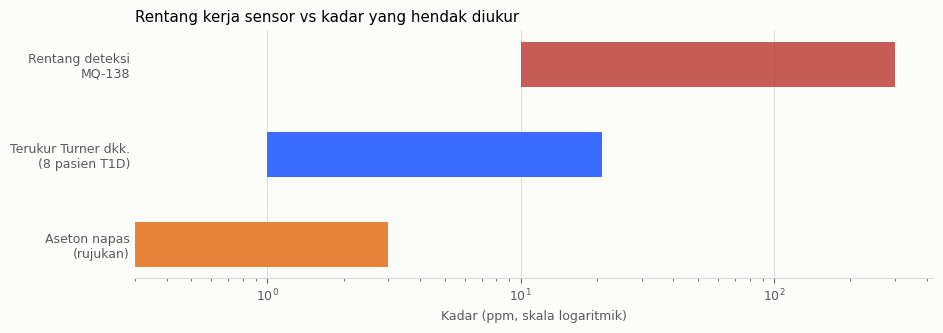

Aseton napas manusia   : 0.3 - 3.0 ppm
Terukur pada Turner    : 1.0 - 21.0 ppm
Rentang deteksi MQ-138 : 10.0 - 300.0 ppm

Batas bawah sensor 3.3x LEBIH TINGGI daripada
kadar aseton napas tertinggi pada orang sehat.

=> Kemampuan MQ-138 membaca kadar aseton napas BELUM TERBUKTI.
   Konversi ke satuan ppm tidak dilakukan; nilai VOC dicatat
   sebagai angka mentah sampai pengujian respons selesai.


In [ ]:
aseton_napas = (0.3, 3.0)      # ppm, kadar aseton napas manusia
mq138 = (10.0, 300.0)          # ppm, rentang deteksi menurut datasheet
turner_asli = (tabel1.aseton_ppm.min(), tabel1.aseton_ppm.max())

fig, ax = plt.subplots(figsize=(9.5, 3.4))
ax.barh(2, mq138[1]-mq138[0], left=mq138[0], height=0.5, color=MERAH, alpha=0.75)
ax.barh(1, turner_asli[1]-turner_asli[0], left=turner_asli[0], height=0.5, color=BIRU)
ax.barh(0, aseton_napas[1]-aseton_napas[0], left=aseton_napas[0], height=0.5, color=JINGGA)
ax.set_yticks([0,1,2], ['Aseton napas\n(rujukan)', 'Terukur Turner dkk.\n(8 pasien T1D)',
                        'Rentang deteksi\nMQ-138'])
ax.set_xscale('log'); ax.set_xlabel('Kadar (ppm, skala logaritmik)')
ax.set_title('Rentang kerja sensor vs kadar yang hendak diukur', loc='left')
ax.grid(axis='x', color=GARIS, lw=0.6); ax.set_axisbelow(True)
for s in ('top','right','left'): ax.spines[s].set_visible(False)
ax.tick_params(axis='y', length=0)
plt.tight_layout(); plt.show()

print(f'Aseton napas manusia   : {aseton_napas[0]} - {aseton_napas[1]} ppm')
print(f'Terukur pada Turner    : {turner_asli[0]} - {turner_asli[1]} ppm')
print(f'Rentang deteksi MQ-138 : {mq138[0]} - {mq138[1]} ppm')
print()
print(f'Batas bawah sensor {mq138[0]/aseton_napas[1]:.1f}x LEBIH TINGGI daripada')
print('kadar aseton napas tertinggi pada orang sehat.')
print()
print('=> Kemampuan MQ-138 membaca kadar aseton napas BELUM TERBUKTI.')
print('   Konversi ke satuan ppm tidak dilakukan; nilai VOC dicatat')
print('   sebagai angka mentah sampai pengujian respons selesai.')


---
# 📌 Kesimpulan Telaah

| Pertanyaan | Jawaban dari data |
|---|---|
| Bisakah ambang tunggal dipakai antar-orang? | **Tidak.** Kadar antar-subjek berbeda hingga 21 kali lipat, r = 0,134 |
| Apakah simulasi setia pada parameter terbitan? | **Ya.** R² dan kemiringan berhimpit; korelasi antar-subjek juga ikut rendah |
| Lebih baik mutlak atau relatif? | **Relatif.** Daya pisah meningkat beberapa kali lipat |
| Sanggupkah sensor kami membacanya? | **Belum terbukti.** Batas deteksi sensor berada di atas kadar napas |

### Yang boleh dan tidak boleh diklaim

- ✅ Hubungan aseton–glukosa **bersumber dari pengukuran laboratorium** (SIFT-MS)
- ✅ Rancangan **patokan personal** terbukti berdasar, bukan sekadar pilihan
- ⚠️ Angka kinerja model berasal dari **simulasi**, bukan pengukuran sensor sendiri
- ❌ **Jangan** menyatakan sensor kami mengukur kadar aseton dalam satuan ppm
